In [1]:
import hashlib
import json
import os
import platform
import subprocess
from importlib.metadata import version
from io import BytesIO
from pathlib import Path

import boto3
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from dotenv import load_dotenv
from IPython.display import display
from lightgbm import LGBMRegressor

# Tìm repo khi mở notebook từ thư mục repo hoặc thư mục models.
repo_root = Path.cwd().resolve()
if not (repo_root / "docker-compose.yml").exists():
    repo_root = repo_root.parent

assert (repo_root / "docker-compose.yml").exists(), "Hãy mở notebook trong repo hoặc models"
assert (repo_root / ".env").exists(), "Cần tạo .env theo .env.example của nhóm"
load_dotenv(repo_root / ".env")

TIMEZONE = "Asia/Shanghai"
REPORT_DIR = repo_root / "models" / "reports" / "pm25_handoff"
EXPERIMENT_NAME = "pm25_forecasting"
REGISTERED_MODEL_NAME = "pm25-forecasting"
FEATURE_SCHEMA_VERSION = "pm25-13-v2-int64-calendar"

# Chỉ bật publish khi đã có link server của Nguyệt.
PUBLISH_MLFLOW = False
NGUYET_MLFLOW_URI = ""
plt.rcParams["figure.dpi"] = 110

print("Python:", platform.python_version())
for package in ["pandas", "numpy", "lightgbm", "scikit-learn", "boto3", "pyarrow", "mlflow"]:
    print(f"{package}: {version(package)}")

Python: 3.11.18
pandas: 2.3.3
numpy: 2.4.6
lightgbm: 4.7.0
scikit-learn: 1.9.1
boto3: 1.40.70
pyarrow: 22.0.0
mlflow: 3.18.0


In [2]:
s3 = boto3.client(
    "s3",
    endpoint_url=os.getenv("MINIO_ENDPOINT", "http://localhost:9000"),
    aws_access_key_id=os.getenv("MINIO_ROOT_USER") or os.getenv("AWS_ACCESS_KEY_ID"),
    aws_secret_access_key=(os.getenv("MINIO_ROOT_PASSWORD") or os.getenv("AWS_SECRET_ACCESS_KEY")),
    region_name=os.getenv("AWS_DEFAULT_REGION", "us-east-1"),
)

bucket = "raw"
prefix = "beijing_pm25"

response = s3.get_object(Bucket=bucket, Key=f"{prefix}/manifest.json")
with response["Body"] as body:
    manifest = json.loads(body.read())

# Git cập nhật code; MinIO giữ dữ liệu trong volume, không tự đổi schema.
raw_columns = [
    "station_id",
    "event_time",
    "pm25_ug_m3",
    "temperature_c",
    "relative_humidity_pct",
    "wind_speed_m_s",
    "wind_direction_deg",
    "precipitation_mm",
]
missing_schema = set(raw_columns) - set(manifest.get("columns", []))
if missing_schema:
    raise ValueError(
        f"MinIO vẫn chứa schema cũ, thiếu {sorted(missing_schema)}. "
        "Cần tạo lại Parquet bằng code ingest mới và cập nhật dữ liệu MinIO; "
        "chỉ restart Docker/Run All không thêm cột. Không tự điền lượng mưa bằng 0."
    )

assert manifest["source_timezone"] == TIMEZONE, "Timezone nguồn khác giả định của notebook"

frames = []
for path, expected_checksum in sorted(manifest["sha256_checksum"].items()):
    response = s3.get_object(Bucket=bucket, Key=f"{prefix}/{path}")
    with response["Body"] as body:
        content = body.read()

    actual_checksum = hashlib.sha256(content).hexdigest()
    assert actual_checksum == expected_checksum, f"Sai checksum: {path}"
    part = pd.read_parquet(BytesIO(content))
    missing = set(raw_columns) - set(part.columns)
    if missing:
        raise ValueError(f"File {path} thiếu cột {sorted(missing)}; kiểm tra lại migration dữ liệu")
    frames.append(part)

assert len(frames) == 60, "Cần toàn bộ 60 file Parquet, không dùng mẫu một tuần"
df = pd.concat(frames, ignore_index=True)
del frames

df["station_id"] = df["station_id"].astype("string")
df["event_time"] = pd.to_datetime(df["event_time"], utc=True)
df = df.sort_values(["station_id", "event_time"]).reset_index(drop=True)

assert len(df) == manifest["row_count"] == 420768
assert df["station_id"].nunique() == manifest["station_count"] == 12
print("Schema raw:", df[raw_columns].columns.tolist())
print("Số cột raw:", len(raw_columns))
print("Số file:", len(manifest["sha256_checksum"]))
print("Số dòng:", len(df))
print("Số trạm:", df["station_id"].nunique())
print("Nguồn:", manifest["source_url"])
display(df.head())

Schema raw: ['station_id', 'event_time', 'pm25_ug_m3', 'temperature_c', 'relative_humidity_pct', 'wind_speed_m_s', 'wind_direction_deg', 'precipitation_mm']
Số cột raw: 8
Số file: 60
Số dòng: 420768
Số trạm: 12
Nguồn: https://www.kaggle.com/datasets/sid321axn/beijing-multisite-airquality-data-set


,station_id,event_time,pm25_ug_m3,temperature_c,relative_humidity_pct,wind_speed_m_s,wind_direction_deg,precipitation_mm
0,beijing_Aotizhongxin,2013-02-28 16:00:00+00:00,4.0,-0.7,24.008842,4.4,337.5,0.0
1,beijing_Aotizhongxin,2013-02-28 17:00:00+00:00,8.0,-1.1,26.013678,4.7,0.0,0.0
2,beijing_Aotizhongxin,2013-02-28 18:00:00+00:00,7.0,-1.1,26.013678,5.6,337.5,0.0
3,beijing_Aotizhongxin,2013-02-28 19:00:00+00:00,6.0,-1.4,24.007753,3.1,315.0,0.0
4,beijing_Aotizhongxin,2013-02-28 20:00:00+00:00,3.0,-2.0,24.876783,2.0,0.0,0.0


## 3. Kiểm tra chất lượng dữ liệu



In [3]:
assert df["station_id"].notna().all()
assert df["event_time"].notna().all()
assert not df.duplicated(["station_id", "event_time"]).any()

hour_gap = df.groupby("station_id")["event_time"].diff()
unexpected_gap = hour_gap.notna() & hour_gap.ne(pd.Timedelta(hours=1))
print("Số khoảng cách khác 1 giờ:", unexpected_gap.sum())
assert not unexpected_gap.any(), "Cần bổ sung lưới giờ từng trạm trước khi tạo lag"

station_summary = df.groupby("station_id").agg(
    so_dong=("event_time", "size"),
    bat_dau_utc=("event_time", "min"),
    ket_thuc_utc=("event_time", "max"),
    thieu_pm25=("pm25_ug_m3", lambda x: x.isna().sum()),
)
display(station_summary)
display(df.isna().sum().rename("so_o_thieu").to_frame())

Số khoảng cách khác 1 giờ: 0


,so_dong,bat_dau_utc,ket_thuc_utc,thieu_pm25
station_id,,,,
beijing_Aotizhongxin,35064,2013-02-28 16:00:00+00:00,2017-02-28 15:00:00+00:00,925
beijing_Changping,35064,2013-02-28 16:00:00+00:00,2017-02-28 15:00:00+00:00,774
beijing_Dingling,35064,2013-02-28 16:00:00+00:00,2017-02-28 15:00:00+00:00,779
beijing_Dongsi,35064,2013-02-28 16:00:00+00:00,2017-02-28 15:00:00+00:00,750
beijing_Guanyuan,35064,2013-02-28 16:00:00+00:00,2017-02-28 15:00:00+00:00,616
beijing_Gucheng,35064,2013-02-28 16:00:00+00:00,2017-02-28 15:00:00+00:00,646
beijing_Huairou,35064,2013-02-28 16:00:00+00:00,2017-02-28 15:00:00+00:00,953
beijing_Nongzhanguan,35064,2013-02-28 16:00:00+00:00,2017-02-28 15:00:00+00:00,628
beijing_Shunyi,35064,2013-02-28 16:00:00+00:00,2017-02-28 15:00:00+00:00,913


,so_o_thieu
station_id,0
event_time,0
pm25_ug_m3,8739
temperature_c,398
relative_humidity_pct,403
wind_speed_m_s,318
wind_direction_deg,1822
precipitation_mm,390


In [4]:
numeric_cols = [
    "pm25_ug_m3",
    "temperature_c",
    "relative_humidity_pct",
    "wind_speed_m_s",
    "wind_direction_deg",
    "precipitation_mm",
]

invalid = pd.DataFrame(
    {
        "pm25_am": df["pm25_ug_m3"] < 0,
        "luong_mua_am": df["precipitation_mm"] < 0,
        "do_am_ngoai_0_100": (
            (df["relative_humidity_pct"] < 0) | (df["relative_humidity_pct"] > 100)
        ),
        "toc_do_gio_am": df["wind_speed_m_s"] < 0,
        "huong_gio_ngoai_0_360": (
            (df["wind_direction_deg"] < 0) | (df["wind_direction_deg"] >= 360)
        ),
    }
)
display(invalid.sum().rename("so_dong_khong_hop_le").to_frame())
assert not invalid.any().any(), "Có giá trị vi phạm; cần kiểm tra nguồn trước khi chạy tiếp"
assert not np.isinf(df[numeric_cols].to_numpy(dtype=float)).any()
display(df[numeric_cols].describe(percentiles=[0.01, 0.5, 0.95, 0.99]).T.round(2))

,so_dong_khong_hop_le
pm25_am,0
luong_mua_am,0
do_am_ngoai_0_100,0
toc_do_gio_am,0
huong_gio_ngoai_0_360,0


,count,mean,std,min,1%,50%,95%,99%,max
pm25_ug_m3,412029.0,79.79,80.82,2.00,3.00,55.00,242.00,370.00,999.0
temperature_c,420370.0,13.54,11.44,-19.90,-7.90,14.50,30.60,33.80,41.6
relative_humidity_pct,420365.0,53.25,25.36,1.69,10.02,52.12,93.95,98.77,100.0
wind_speed_m_s,420450.0,1.73,1.25,0.00,0.00,1.40,4.30,6.10,13.2
wind_direction_deg,418946.0,157.46,108.64,0.00,0.00,135.00,337.50,337.50,337.5
precipitation_mm,420378.0,0.06,0.82,0.00,0.00,0.00,0.00,1.40,72.5


### Kiểm tra các đỉnh PM2.5


In [5]:
peak_index = df["pm25_ug_m3"].idxmax()
peak_time = df.loc[peak_index, "event_time"]
peak_station = df.loc[peak_index, "station_id"]

around_peak = df["station_id"].eq(peak_station) & df["event_time"].between(
    peak_time - pd.Timedelta(hours=3), peak_time + pd.Timedelta(hours=3)
)
display(df.loc[around_peak, ["station_id", "event_time", "pm25_ug_m3"]])
display(
    df.loc[df["event_time"].eq(peak_time), ["station_id", "event_time", "pm25_ug_m3"]].sort_values(
        "pm25_ug_m3", ascending=False
    )
)

,station_id,event_time,pm25_ug_m3
411479,beijing_Wanshouxigong,2016-02-07 15:00:00+00:00,171.0
411480,beijing_Wanshouxigong,2016-02-07 16:00:00+00:00,238.0
411481,beijing_Wanshouxigong,2016-02-07 17:00:00+00:00,826.0
411482,beijing_Wanshouxigong,2016-02-07 18:00:00+00:00,999.0
411483,beijing_Wanshouxigong,2016-02-07 19:00:00+00:00,857.0
411484,beijing_Wanshouxigong,2016-02-07 20:00:00+00:00,748.0
411485,beijing_Wanshouxigong,2016-02-07 21:00:00+00:00,662.0


,station_id,event_time,pm25_ug_m3
411482,beijing_Wanshouxigong,2016-02-07 18:00:00+00:00,999.0
376418,beijing_Wanliu,2016-02-07 18:00:00+00:00,957.0
306290,beijing_Shunyi,2016-02-07 18:00:00+00:00,941.0
25778,beijing_Aotizhongxin,2016-02-07 18:00:00+00:00,898.0
60842,beijing_Changping,2016-02-07 18:00:00+00:00,882.0
130970,beijing_Dongsi,2016-02-07 18:00:00+00:00,642.0
95906,beijing_Dingling,2016-02-07 18:00:00+00:00,610.0
201098,beijing_Gucheng,2016-02-07 18:00:00+00:00,536.0
166034,beijing_Guanyuan,2016-02-07 18:00:00+00:00,534.0
341354,beijing_Tiantan,2016-02-07 18:00:00+00:00,508.0


## 4. Tạo nhãn và đặc trưng


In [6]:
data = df.copy()
grouped = data.groupby("station_id")["pm25_ug_m3"]

data["target"] = grouped.shift(-1)
data["target_time"] = data["event_time"] + pd.Timedelta(hours=1)

for lag in [1, 3, 24]:
    data[f"pm25_lag_{lag}h"] = grouped.shift(lag)

local_time = data["event_time"].dt.tz_convert(TIMEZONE)
data["hour"] = local_time.dt.hour
data["weekday"] = local_time.dt.dayofweek
data["month"] = local_time.dt.month

missing_current = data["pm25_ug_m3"].isna()
missing_target = data["target"].isna()
print("Tổng số dòng:", len(data))
print("Thiếu PM2.5 hiện tại:", missing_current.sum())
print("Có PM2.5 hiện tại nhưng thiếu nhãn:", ((~missing_current) & missing_target).sum())
print("Số dòng cần loại:", (missing_current | missing_target).sum())

# Chỉ loại sau khi đã tạo xong lag.
model_data = data.dropna(subset=["pm25_ug_m3", "target"]).copy()
print("Số dòng còn lại:", len(model_data))

Tổng số dòng: 420768
Thiếu PM2.5 hiện tại: 8739
Có PM2.5 hiện tại nhưng thiếu nhãn: 2849
Số dòng cần loại: 11588
Số dòng còn lại: 409180


## 5. Chia train/test theo thời điểm nhãn



In [7]:
train_start = pd.Timestamp("2013-01-01", tz=TIMEZONE)
train_end = pd.Timestamp("2016-01-01", tz=TIMEZONE)
test_start = pd.Timestamp("2016-01-01", tz=TIMEZONE)
test_end = pd.Timestamp("2017-01-01", tz=TIMEZONE)

target_local = model_data["target_time"].dt.tz_convert(TIMEZONE)
train = model_data.loc[(target_local >= train_start) & (target_local < train_end)].copy()
test = model_data.loc[(target_local >= test_start) & (target_local < test_end)].copy()

assert len(train) > 0 and len(test) > 0
assert train["target_time"].max() < test["target_time"].min()
print("Số mẫu train:", len(train))
print("Số mẫu test:", len(test))
for name, frame in [("Train", train), ("Test", test)]:
    times = frame["target_time"].dt.tz_convert(TIMEZONE)
    print(name, "— nhãn từ", times.min(), "đến", times.max())

test["target_month"] = test["target_time"].dt.tz_convert(TIMEZONE).dt.strftime("%Y-%m")
monthly_counts = pd.crosstab(test["target_month"], test["station_id"])
expected_months = pd.period_range("2016-01", "2016-12", freq="M").astype(str).tolist()
assert monthly_counts.index.tolist() == expected_months
assert monthly_counts.shape[1] == 12
assert (monthly_counts > 0).all().all()
display(monthly_counts)
print("Test đủ 12 tháng và mỗi tháng có mẫu của cả 12 trạm.")

Số mẫu train: 290312
Số mẫu test: 102298
Train — nhãn từ 2013-03-01 01:00:00+08:00 đến 2015-12-31 23:00:00+08:00
Test — nhãn từ 2016-01-01 00:00:00+08:00 đến 2016-12-31 23:00:00+08:00


station_id,beijing_Aotizhongxin,beijing_Changping,beijing_Dingling,beijing_Dongsi,beijing_Guanyuan,beijing_Gucheng,beijing_Huairou,beijing_Nongzhanguan,beijing_Shunyi,beijing_Tiantan,beijing_Wanliu,beijing_Wanshouxigong
target_month,,,,,,,,,,,,
2016-01,729,733,716,742,742,735,731,741,736,738,741,734
2016-02,689,684,680,690,692,686,654,692,685,690,684,688
2016-03,699,722,721,707,724,721,725,721,705,721,720,724
2016-04,675,699,688,673,698,692,683,694,642,677,700,685
2016-05,732,719,709,705,734,722,728,717,672,735,727,714
2016-06,697,702,717,658,711,708,714,717,699,705,706,641
2016-07,710,725,726,609,685,733,721,732,704,735,734,727
2016-08,732,728,728,736,738,739,729,742,725,728,738,735
2016-09,690,691,652,684,690,655,672,691,628,686,693,686


Test đủ 12 tháng và mỗi tháng có mẫu của cả 12 trạm.


Tỷ lệ mẫu test hợp lệ theo tháng và trạm (%):


station_id,beijing_Aotizhongxin,beijing_Changping,beijing_Dingling,beijing_Dongsi,beijing_Guanyuan,beijing_Gucheng,beijing_Huairou,beijing_Nongzhanguan,beijing_Shunyi,beijing_Tiantan,beijing_Wanliu,beijing_Wanshouxigong
target_month,,,,,,,,,,,,
2016-01,97.98,98.52,96.24,99.73,99.73,98.79,98.25,99.60,98.92,99.19,99.60,98.66
2016-02,98.99,98.28,97.70,99.14,99.43,98.56,93.97,99.43,98.42,99.14,98.28,98.85
2016-03,93.95,97.04,96.91,95.03,97.31,96.91,97.45,96.91,94.76,96.91,96.77,97.31
2016-04,93.75,97.08,95.56,93.47,96.94,96.11,94.86,96.39,89.17,94.03,97.22,95.14
2016-05,98.39,96.64,95.30,94.76,98.66,97.04,97.85,96.37,90.32,98.79,97.72,95.97
2016-06,96.81,97.50,99.58,91.39,98.75,98.33,99.17,99.58,97.08,97.92,98.06,89.03
2016-07,95.43,97.45,97.58,81.85,92.07,98.52,96.91,98.39,94.62,98.79,98.66,97.72
2016-08,98.39,97.85,97.85,98.92,99.19,99.33,97.98,99.73,97.45,97.85,99.19,98.79
2016-09,95.83,95.97,90.56,95.00,95.83,90.97,93.33,95.97,87.22,95.28,96.25,95.28


Đánh giá 102298/105408 mẫu (97.05%).


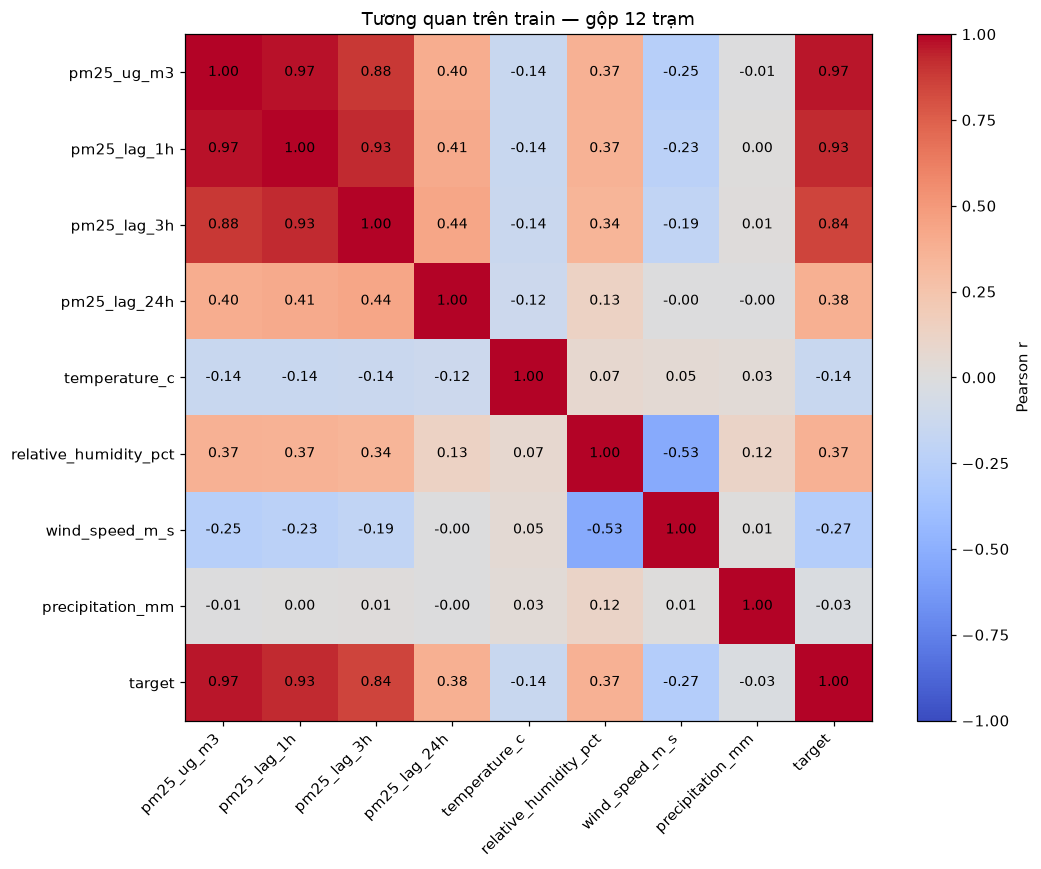

In [8]:
expected_hours = pd.Series(
    [pd.Period(month, freq="M").days_in_month * 24 for month in expected_months],
    index=expected_months,
)
coverage_pct = monthly_counts.div(expected_hours, axis=0) * 100
print("Tỷ lệ mẫu test hợp lệ theo tháng và trạm (%):")
display(coverage_pct.round(2))
expected_total = int(expected_hours.sum() * monthly_counts.shape[1])
print(f"Đánh giá {len(test)}/{expected_total} mẫu ({100 * len(test) / expected_total:.2f}%).")

corr_cols = [
    "pm25_ug_m3",
    "pm25_lag_1h",
    "pm25_lag_3h",
    "pm25_lag_24h",
    "temperature_c",
    "relative_humidity_pct",
    "wind_speed_m_s",
    "precipitation_mm",
    "target",
]
corr = train[corr_cols].corr()
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9)
fig.colorbar(im, ax=ax, label="Pearson r")
ax.set_title("Tương quan trên train — gộp 12 trạm")
plt.tight_layout()
plt.show()

## 6. Persistence —



In [9]:
predictions = test[["station_id", "target_time", "target_month", "target"]].copy()
predictions = predictions.rename(columns={"target": "actual"})
predictions["Persistence"] = test["pm25_ug_m3"]
display(predictions.head())

,station_id,target_time,target_month,actual,Persistence
24863,beijing_Aotizhongxin,2015-12-31 16:00:00+00:00,2016-01,209.0,193.0
24864,beijing_Aotizhongxin,2015-12-31 17:00:00+00:00,2016-01,211.0,209.0
24865,beijing_Aotizhongxin,2015-12-31 18:00:00+00:00,2016-01,167.0,211.0
24866,beijing_Aotizhongxin,2015-12-31 19:00:00+00:00,2016-01,136.0,167.0
24867,beijing_Aotizhongxin,2015-12-31 20:00:00+00:00,2016-01,108.0,136.0


## 7. LightGBM — 13 đặc trưng



In [10]:
features = [
    "station_id",
    "pm25_ug_m3",
    "pm25_lag_1h",
    "pm25_lag_3h",
    "pm25_lag_24h",
    "hour",
    "weekday",
    "month",
    "temperature_c",
    "relative_humidity_pct",
    "wind_speed_m_s",
    "wind_direction_deg",
    "precipitation_mm",
]

X_train = train[features].copy()
X_test = test[features].copy()
y_train = train["target"]
y_test = test["target"]

assert set(test["station_id"]) <= set(train["station_id"])
# Chỉ tạo mapping từ train; dùng lại đúng mapping khi dự báo/log model.
station_mapping = {
    str(station): code for code, station in enumerate(sorted(train["station_id"].unique()))
}
for frame in (X_train, X_test):
    frame["station_id"] = frame["station_id"].map(station_mapping)
    assert frame["station_id"].notna().all(), "Có trạm chưa có trong mapping train"

# Ma trận nội bộ của LightGBM dùng float64; model bàn giao vẫn nhận tên trạm.
# Đây là đổi dtype, không scale các giá trị về 0–1.
X_train = X_train.astype("float64")
X_test = X_test.astype("float64")
assert X_test.index.equals(predictions.index)
assert y_test.equals(predictions["actual"])

display(X_train.isna().sum().rename("NaN_train").to_frame())
display(pd.Series(station_mapping, name="station_code").to_frame())
display(X_train.dtypes.rename("input_dtype").to_frame())

,NaN_train
station_id,0
pm25_ug_m3,0
pm25_lag_1h,1736
pm25_lag_3h,2660
pm25_lag_24h,4708
hour,0
weekday,0
month,0
temperature_c,177
relative_humidity_pct,182


,station_code
beijing_Aotizhongxin,0
beijing_Changping,1
beijing_Dingling,2
beijing_Dongsi,3
beijing_Guanyuan,4
beijing_Gucheng,5
beijing_Huairou,6
beijing_Nongzhanguan,7
beijing_Shunyi,8
beijing_Tiantan,9


,input_dtype
station_id,float64
pm25_ug_m3,float64
pm25_lag_1h,float64
pm25_lag_3h,float64
pm25_lag_24h,float64
hour,float64
weekday,float64
month,float64
temperature_c,float64
relative_humidity_pct,float64


In [11]:
import time

model = LGBMRegressor(
    n_estimators=300,
    learning_rate=0.05,
    num_leaves=31,
    random_state=42,
    n_jobs=2,
    verbosity=-1,
)

cpu_start = time.process_time()
wall_start = time.perf_counter()
model.fit(X_train, y_train, categorical_feature=["station_id"])
train_cpu_seconds = time.process_time() - cpu_start
train_wall_seconds = time.perf_counter() - wall_start
training_timestamp_utc = pd.Timestamp.now(tz="UTC").isoformat()
print(f"CPU time: {train_cpu_seconds:.3f} giây")
print(f"Wall time: {train_wall_seconds:.3f} giây")
predictions["LightGBM"] = model.predict(X_test)
assert np.isfinite(predictions[["actual", "Persistence", "LightGBM"]]).all().all()
print("Đã huấn luyện LightGBM một lần và dự đoán trên cùng tập test với Persistence.")

CPU time: 9.436 giây
Wall time: 5.411 giây
Đã huấn luyện LightGBM một lần và dự đoán trên cùng tập test với Persistence.


## 8. Bảng MAE/RMSE tổng thể


In [12]:
def metric_row(frame, model_name):
    error = frame["actual"] - frame[model_name]
    return {
        "Model": model_name,
        "MAE": error.abs().mean(),
        "RMSE": error.pow(2).mean() ** 0.5,
        "So_mau": len(frame),
    }


model_names = ["Persistence", "LightGBM"]
results = pd.DataFrame([metric_row(predictions, name) for name in model_names])
# Chi phí huấn luyện: Persistence không có bước fit nên là 0.
# train_cpu_seconds lấy từ cell fit ở mục 7 (time.process_time bao quanh model.fit).
results["Train_CPU_giay"] = [0.0, train_cpu_seconds]
display(results.round(3))

comparison = results.set_index("Model")
for metric in ["MAE", "RMSE"]:
    baseline = comparison.loc["Persistence", metric]
    learned = comparison.loc["LightGBM", metric]
    if baseline > 0:
        change_pct = 100 * (baseline - learned) / baseline
        print(f"{metric}: LightGBM cải thiện {change_pct:.2f}% so với Persistence.")
print("Cải thiện âm nghĩa là LightGBM có sai số cao hơn Persistence.")

,Model,MAE,RMSE,So_mau,Train_CPU_giay
0,Persistence,9.663,18.616,102298,0.000
1,LightGBM,9.022,17.387,102298,9.436


MAE: LightGBM cải thiện 6.64% so với Persistence.
RMSE: LightGBM cải thiện 6.60% so với Persistence.
Cải thiện âm nghĩa là LightGBM có sai số cao hơn Persistence.


## 9. Sai số theo trạm



In [13]:
station_rows = []
for station, frame in predictions.groupby("station_id", observed=True):
    for name in model_names:
        station_rows.append({"station_id": station, **metric_row(frame, name)})

station_results = pd.DataFrame(station_rows)
assert len(station_results) == 24
display(station_results.round(3))

,station_id,Model,MAE,RMSE,So_mau
0,beijing_Aotizhongxin,Persistence,9.898,18.938,8541
1,beijing_Aotizhongxin,LightGBM,9.139,17.861,8541
2,beijing_Changping,Persistence,8.939,16.356,8594
3,beijing_Changping,LightGBM,8.410,14.464,8594
4,beijing_Dingling,Persistence,8.409,19.962,8394
5,beijing_Dingling,LightGBM,8.036,18.820,8394
6,beijing_Dongsi,Persistence,10.411,19.718,8353
7,beijing_Dongsi,LightGBM,9.645,18.478,8353
8,beijing_Guanyuan,Persistence,9.997,17.769,8594
9,beijing_Guanyuan,LightGBM,9.232,16.434,8594


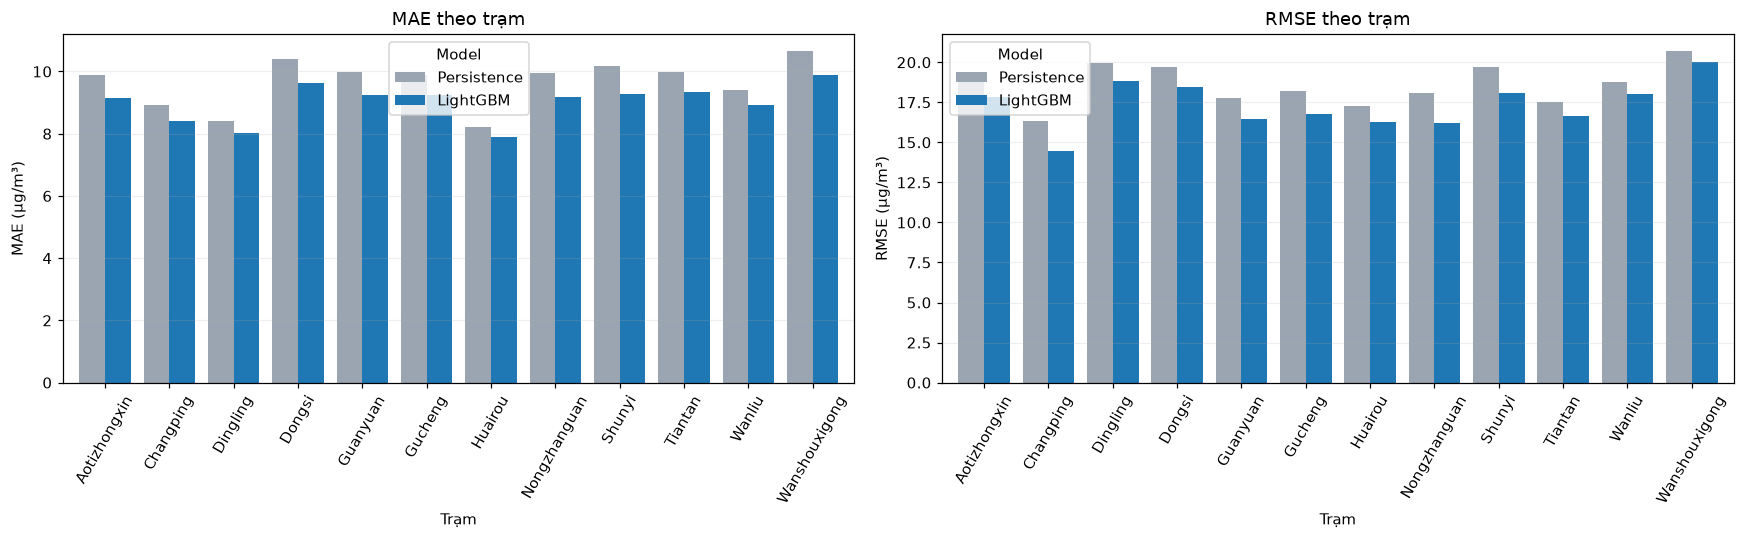

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, metric in zip(axes, ["MAE", "RMSE"]):
    table = station_results.pivot(index="station_id", columns="Model", values=metric)
    table.index = table.index.str.replace("beijing_", "", regex=False)
    table[model_names].plot.bar(ax=ax, color=["#9aa5b1", "#1f77b4"], width=0.8)
    ax.set_title(f"{metric} theo trạm")
    ax.set_xlabel("Trạm")
    ax.set_ylabel(f"{metric} (µg/m³)")
    ax.tick_params(axis="x", rotation=60)
    ax.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

## 10. Sai số theo tháng — đủ 12 tháng


In [15]:
monthly_rows = []
for month, frame in predictions.groupby("target_month"):
    for name in model_names:
        monthly_rows.append({"Month": month, **metric_row(frame, name)})

monthly_results = pd.DataFrame(monthly_rows)
assert monthly_results["Month"].unique().tolist() == expected_months
assert len(monthly_results) == 24
display(monthly_results.round(3))

,Month,Model,MAE,RMSE,So_mau
0,2016-01,Persistence,10.077,18.723,8818
1,2016-01,LightGBM,9.311,17.001,8818
2,2016-02,Persistence,8.949,27.507,8214
3,2016-02,LightGBM,8.552,27.326,8214
4,2016-03,Persistence,9.796,17.847,8610
5,2016-03,LightGBM,9.130,16.318,8610
6,2016-04,Persistence,10.243,17.716,8206
7,2016-04,LightGBM,9.458,15.979,8206
8,2016-05,Persistence,9.390,16.871,8614
9,2016-05,LightGBM,9.277,18.087,8614


### Biểu đồ đường

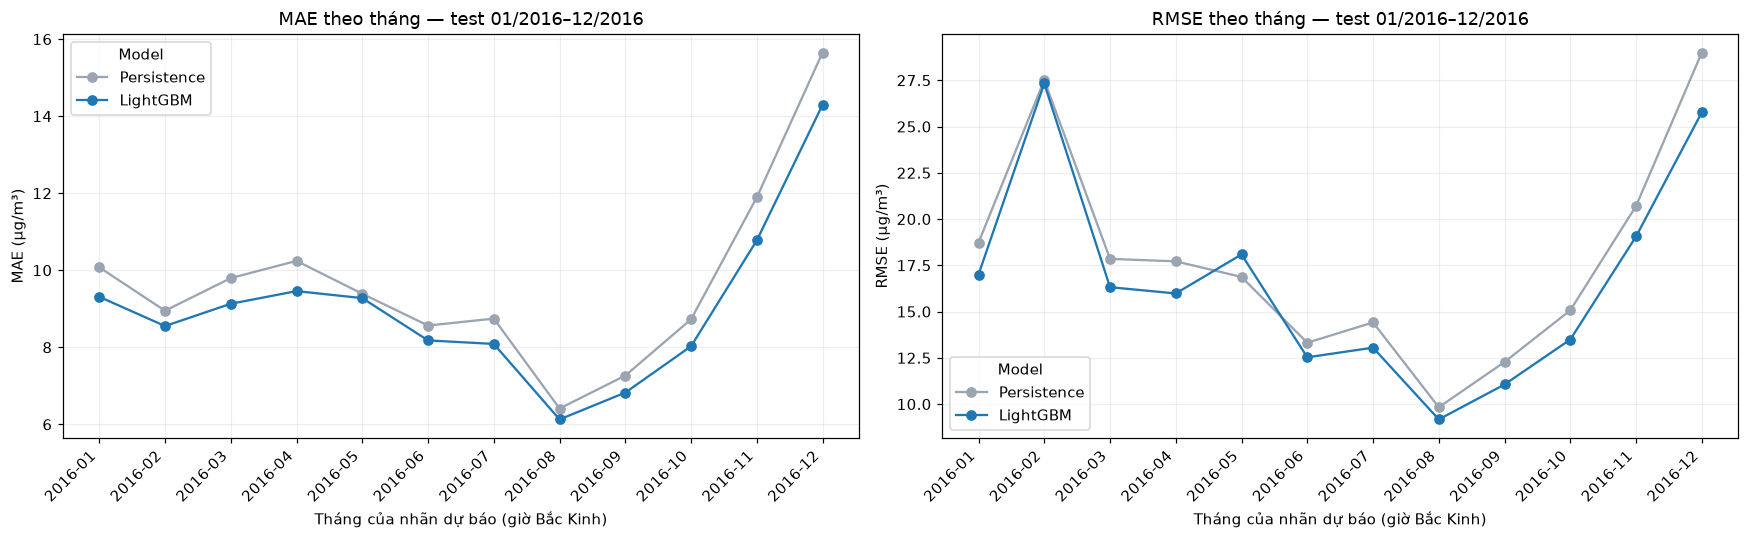

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, metric in zip(axes, ["MAE", "RMSE"]):
    table = monthly_results.pivot(index="Month", columns="Model", values=metric)
    table[model_names].plot(ax=ax, marker="o", color=["#9aa5b1", "#1f77b4"])
    ax.set_title(f"{metric} theo tháng — test 01/2016–12/2016")
    ax.set_xlabel("Tháng của nhãn dự báo (giờ Bắc Kinh)")
    ax.set_ylabel(f"{metric} (µg/m³)")
    ax.set_xticks(range(len(table)))
    ax.set_xticklabels(table.index, rotation=45, ha="right")
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## 11. Độ quan trọng của đặc trưng 


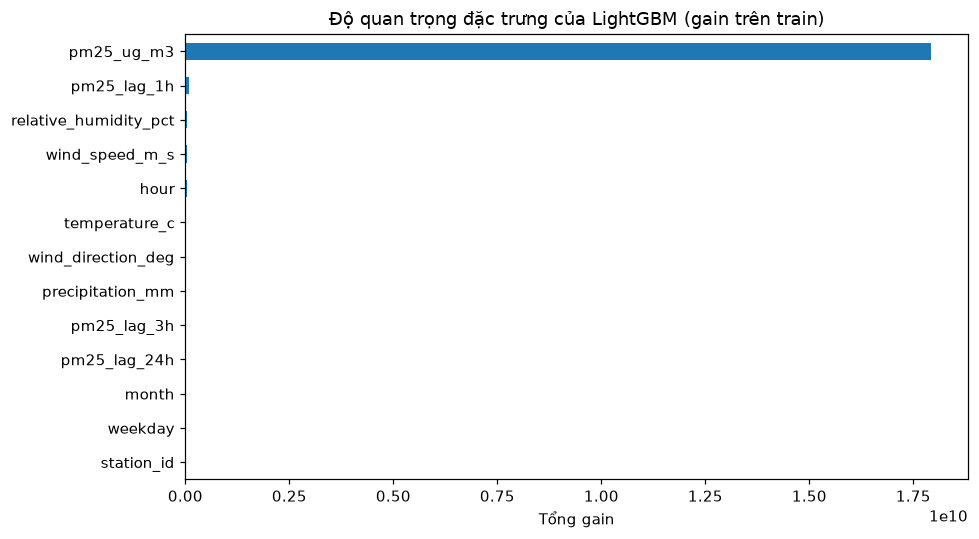

In [17]:
importance = pd.Series(
    model.booster_.feature_importance(importance_type="gain"),
    index=features,
).sort_values()

importance.plot.barh(figsize=(9, 5), color="#1f77b4")
plt.title("Độ quan trọng đặc trưng của LightGBM (gain trên train)")
plt.xlabel("Tổng gain")
plt.tight_layout()
plt.show()

### Phóng to các đặc trưng còn lại



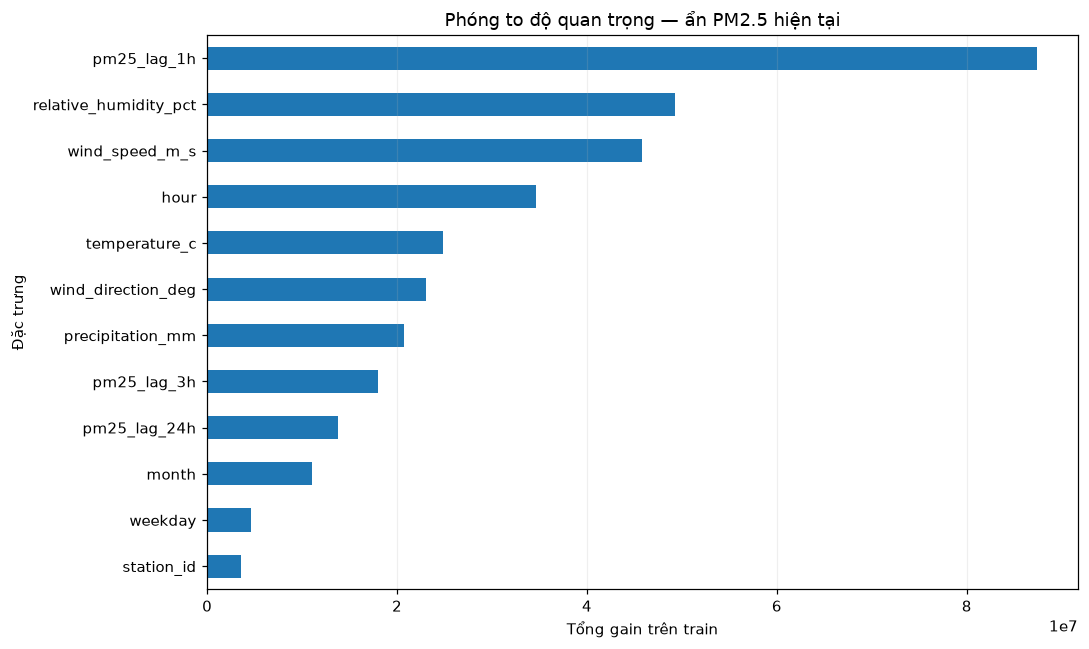

In [18]:
importance_zoom = importance.drop("pm25_ug_m3").sort_values()

importance_zoom.plot.barh(figsize=(10, 6), color="#1f77b4")
plt.title("Phóng to độ quan trọng — ẩn PM2.5 hiện tại")
plt.xlabel("Tổng gain trên train")
plt.ylabel("Đặc trưng")
plt.grid(axis="x", alpha=0.2)
plt.tight_layout()
plt.show()

## 12. Đóng gói model tự encode




In [19]:
import mlflow
import mlflow.pyfunc
from mlflow.models import infer_signature


class PM25ServingModel(mlflow.pyfunc.PythonModel):
    """LightGBM đã fit kèm encoder cố định; nhận tên trạm gốc."""

    def __init__(self, fitted_model, station_mapping, features):
        self.fitted_model = fitted_model
        self.station_mapping = dict(station_mapping)
        self.features = list(features)

    def predict(self, context, model_input, params=None):
        frame = pd.DataFrame(model_input).copy()
        missing = set(self.features) - set(frame.columns)
        if missing:
            raise ValueError(f"Thiếu feature: {sorted(missing)}")
        frame = frame[self.features].copy()
        station = frame["station_id"]
        if station.isna().any() or not station.map(lambda x: isinstance(x, str)).all():
            raise ValueError("station_id phải là chuỗi không thiếu")
        station = station.str.strip()
        if station.eq("").any():
            raise ValueError("station_id không được rỗng")
        # Trạm mới -> NaN categorical; không mượn mã của một trạm đã biết.
        frame["station_id"] = station.map(self.station_mapping)
        for column in self.features:
            frame[column] = pd.to_numeric(frame[column], errors="raise").astype("float64")
        if np.isinf(frame.to_numpy()).any():
            raise ValueError("Input chứa inf hoặc -inf")
        required = ["pm25_ug_m3", "hour", "weekday", "month"]
        if frame[required].isna().any().any():
            raise ValueError("Thiếu PM2.5 hiện tại hoặc biến lịch bắt buộc")
        for column, low, high in [("hour", 0, 23), ("weekday", 0, 6), ("month", 1, 12)]:
            values = frame[column]
            if (~values.between(low, high) | values.mod(1).ne(0)).any():
                raise ValueError(f"{column} phải là số nguyên trong [{low}, {high}]")
        for column in ["pm25_ug_m3", "wind_speed_m_s", "precipitation_mm"]:
            if frame[column].lt(0).any():
                raise ValueError(f"{column} không được âm")
        for column, low, high in [
            ("relative_humidity_pct", 0, 100),
            ("wind_direction_deg", 0, 360),
        ]:
            values = frame[column].dropna()
            if (~values.between(low, high)).any():
                raise ValueError(f"{column} ngoài [{low}, {high}]")
        return np.maximum(self.fitted_model.predict(frame), 0.0)


serving_model = PM25ServingModel(model, station_mapping, features)
X_test_input = test[features].copy()
X_test_input["station_id"] = X_test_input["station_id"].astype(str)
calendar_columns = ["hour", "weekday", "month"]
for column in features:
    if column in calendar_columns:
        X_test_input[column] = X_test_input[column].astype("int64")
    elif column != "station_id":
        X_test_input[column] = X_test_input[column].astype("float64")
assert all(X_test_input[column].dtype == np.dtype("int64") for column in calendar_columns)

serving_predictions = serving_model.predict(None, X_test_input)
np.testing.assert_allclose(serving_predictions, np.maximum(predictions["LightGBM"].to_numpy(), 0.0))
predictions["LightGBM_serving"] = serving_predictions
serving_results = pd.DataFrame(
    [metric_row(predictions, name) for name in ["Persistence", "LightGBM_serving"]]
)
print("Model tự encode khớp dự đoán LightGBM sau clip trên toàn bộ test.")
print("Số dự đoán raw âm:", int((predictions["LightGBM"] < 0).sum()))
display(serving_results.round(3))
# Infer từ input bên ngoài, không infer từ ma trận float64 đã encode bên trong.
signature = infer_signature(X_test_input, serving_predictions)
display(X_test_input.dtypes.rename("serving_input_dtype").to_frame())
print("Signature đầu vào:", signature.inputs)

/home/thien/Bản tải về/projectHKDN/Nhom4-HKDN_2026-2027/.venv/lib/python3.11/site-packages/mlflow/pyfunc/utils/data_validation.py:187: UserWarning: Add type hints to the `predict` method to enable data validation and automatic signature inference during model logging. Check https://mlflow.org/docs/latest/model/python_model.html#type-hint-usage-in-pythonmodel for more details.
  color_warning(


Model tự encode khớp dự đoán LightGBM sau clip trên toàn bộ test.
Số dự đoán raw âm: 13


,Model,MAE,RMSE,So_mau
0,Persistence,9.663,18.616,102298
1,LightGBM_serving,9.021,17.386,102298


/home/thien/Bản tải về/projectHKDN/Nhom4-HKDN_2026-2027/.venv/lib/python3.11/site-packages/mlflow/types/utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


,serving_input_dtype
station_id,object
pm25_ug_m3,float64
pm25_lag_1h,float64
pm25_lag_3h,float64
pm25_lag_24h,float64
hour,int64
weekday,int64
month,int64
temperature_c,float64
relative_humidity_pct,float64


Signature đầu vào: ['station_id': string (required), 'pm25_ug_m3': double (required), 'pm25_lag_1h': double (optional), 'pm25_lag_3h': double (optional), 'pm25_lag_24h': double (optional), 'hour': long (required), 'weekday': long (required), 'month': long (required), 'temperature_c': double (optional), 'relative_humidity_pct': double (optional), 'wind_speed_m_s': double (optional), 'wind_direction_deg': double (optional), 'precipitation_mm': double (optional)]


## 13. Xuất bộ bàn giao đầy đủ




In [20]:
REPORT_DIR.mkdir(parents=True, exist_ok=True)
# Không để receipt của lần log trước bị hiểu là kết quả mới.
(REPORT_DIR / "mlflow_receipt.json").unlink(missing_ok=True)


def write_json(path, payload):
    path.write_text(json.dumps(payload, ensure_ascii=False, indent=2, allow_nan=False) + "\n")


handoff_predictions = predictions.rename(
    columns={
        "Persistence": "persistence_prediction",
        "LightGBM": "lightgbm_raw_prediction",
        "LightGBM_serving": "lightgbm_serving_prediction",
    }
).copy()
handoff_predictions.insert(1, "event_time", test["event_time"])
handoff_predictions["error_serving"] = (
    handoff_predictions["lightgbm_serving_prediction"] - handoff_predictions["actual"]
)
handoff_predictions["absolute_error_serving"] = handoff_predictions["error_serving"].abs()
handoff_predictions["squared_error_serving"] = handoff_predictions["error_serving"].pow(2)
assert len(handoff_predictions) == len(X_test_input) == len(test)
assert not handoff_predictions.duplicated(["station_id", "target_time"]).any()
assert (
    np.isfinite(
        handoff_predictions[
            [
                "actual",
                "persistence_prediction",
                "lightgbm_raw_prediction",
                "lightgbm_serving_prediction",
            ]
        ]
    )
    .all()
    .all()
)

handoff_predictions.to_csv(REPORT_DIR / "test_predictions.csv", index=False)
X_test_input.to_parquet(REPORT_DIR / "test_inputs.parquet", index=False)
results.to_csv(REPORT_DIR / "metrics_raw.csv", index=False)
serving_results.to_csv(REPORT_DIR / "metrics_serving.csv", index=False)
station_results.to_csv(REPORT_DIR / "metrics_by_station_raw.csv", index=False)
monthly_results.to_csv(REPORT_DIR / "metrics_by_month_raw.csv", index=False)
coverage_pct.to_csv(REPORT_DIR / "coverage_by_month_station.csv")

input_example = X_test_input.dropna().head(2).copy()
assert not input_example.empty, "Cần ít nhất một input mẫu đầy đủ"
write_json(REPORT_DIR / "predict_request.json", {"features": input_example.to_dict("records")})
null_example = input_example.copy()
null_example.loc[null_example.index[0], ["pm25_lag_1h", "precipitation_mm"]] = np.nan
write_json(
    REPORT_DIR / "predict_request_with_null.json",
    {"features": json.loads(null_example.to_json(orient="records"))},
)
preprocessing = {
    "feature_schema_version": FEATURE_SCHEMA_VERSION,
    "features": features,
    "external_types": {
        name: "string"
        if name == "station_id"
        else "int64"
        if name in calendar_columns
        else "float64"
        for name in features
    },
    "station_mapping": station_mapping,
    "unknown_station_policy": "nonempty_unseen_string_to_categorical_NaN",
    "internal_dtype": "float64",
    "calendar_input_dtype": "int64",
    "missing_lags_weather": "preserve_NaN",
    "required_non_null": ["station_id", "pm25_ug_m3", "hour", "weekday", "month"],
    "output": "nonnegative PM2.5 ug/m3; clip at 0",
    "calendar_timezone": "station local timezone; Beijing=Asia/Shanghai, VN=Asia/Ho_Chi_Minh",
    "vietnam_accuracy_validated": False,
}
write_json(REPORT_DIR / "preprocessing.json", preprocessing)

dataset_version = hashlib.sha256(json.dumps(manifest, sort_keys=True).encode()).hexdigest()
try:
    git_commit = subprocess.check_output(
        ["git", "rev-parse", "HEAD"], cwd=repo_root, text=True
    ).strip()
    git_dirty = bool(
        subprocess.check_output(
            ["git", "status", "--porcelain", "--untracked-files=no"], cwd=repo_root, text=True
        ).strip()
    )
except (FileNotFoundError, subprocess.CalledProcessError):
    git_commit, git_dirty = None, None

evaluation_context = {
    "model_name": REGISTERED_MODEL_NAME,
    "experiment_name": EXPERIMENT_NAME,
    "model_strategy": "static_1h_baseline_no_retraining_in_test",
    "feature_schema_version": FEATURE_SCHEMA_VERSION,
    "training_timestamp_utc": training_timestamp_utc,
    "dataset_version": dataset_version,
    "dataset_manifest": manifest,
    "git_commit": git_commit,
    "git_dirty": git_dirty,
    "train_start_inclusive": train_start.isoformat(),
    "train_end_exclusive": train_end.isoformat(),
    "test_start_inclusive": test_start.isoformat(),
    "test_end_exclusive": test_end.isoformat(),
    "split_by": "target_time",
    "timezone": TIMEZONE,
    "train_samples": len(train),
    "test_samples": len(test),
    "expected_test_samples": expected_total,
    "test_coverage_pct": 100.0 * len(test) / expected_total,
    "station_count": int(test["station_id"].nunique()),
    "test_months": expected_months,
    "raw_vs_serving": "mae/rmse logged for clipped serving output; raw metrics also included",
    "input_alignment": "row i of test_inputs.parquet matches row i of test_predictions.csv",
    "train_cpu_seconds": float(train_cpu_seconds),
    "train_wall_seconds": float(train_wall_seconds),
    "n_jobs": model.get_params()["n_jobs"],
    "python": platform.python_version(),
    "platform": platform.platform(),
    "package_versions": {
        name: version(name) for name in ["mlflow", "lightgbm", "numpy", "pandas", "cloudpickle"]
    },
    "initial_mentor_test_period": "2016-03 to 2017-02; current user-selected split differs",
    "rollback_thresholds_calibrated": False,
}
write_json(REPORT_DIR / "evaluation_context.json", evaluation_context)
print("Bộ bàn giao:", REPORT_DIR)
print("Số dòng test thực tế:", len(test), "— không dùng số của bản test khác.")
print("CPU gửi Phú:", train_cpu_seconds, "giây; wall time:", train_wall_seconds, "giây.")

Bộ bàn giao: /home/thien/Bản tải về/projectHKDN/Nhom4-HKDN_2026-2027/models/reports/pm25_handoff
Số dòng test thực tế: 102298 — không dùng số của bản test khác.
CPU gửi Phú: 9.435757409999999 giây; wall time: 5.411214574999576 giây.


## 14. Log lên MLflow và bàn giao



In [21]:
if PUBLISH_MLFLOW:
    if not NGUYET_MLFLOW_URI.strip():
        raise ValueError("Bạn chưa điền link MLflow của Nguyệt")
    # Tự tính metric tại đây; không phụ thuộc mục kiểm tra champion đã bỏ.
    required_columns = ["actual", "Persistence", "LightGBM", "LightGBM_serving"]
    missing_columns = set(required_columns) - set(predictions.columns)
    if predictions.empty or missing_columns:
        raise ValueError(f"Thiếu dữ liệu đánh giá: {sorted(missing_columns)}")
    values = predictions[required_columns].to_numpy(dtype=float)
    if not np.isfinite(values).all():
        raise ValueError("Dữ liệu đánh giá chứa NaN/inf; không ghi cứng hoặc bỏ qua metric")

    metrics = {}
    for prefix, column in [
        ("", "LightGBM_serving"),
        ("persistence_", "Persistence"),
        ("raw_", "LightGBM"),
    ]:
        error = predictions["actual"].to_numpy(dtype=float) - predictions[column].to_numpy(
            dtype=float
        )
        metrics[f"{prefix}mae"] = float(np.abs(error).mean())
        metrics[f"{prefix}rmse"] = float(np.sqrt(np.square(error).mean()))
    metrics.update(
        train_cpu_seconds=float(train_cpu_seconds),
        train_wall_seconds=float(train_wall_seconds),
        test_coverage_pct=float(evaluation_context["test_coverage_pct"]),
    )
    metric_values = np.array(list(metrics.values()), dtype=float)
    if not np.isfinite(metric_values).all() or (metric_values < 0).any():
        raise ValueError("Metric đánh giá/chi phí không hợp lệ")
    mlflow.set_tracking_uri(NGUYET_MLFLOW_URI.strip())
    mlflow.set_experiment(EXPERIMENT_NAME)
    with mlflow.start_run(run_name="lightgbm-beijing-baseline") as run:
        mlflow.log_params(model.get_params())
        mlflow.log_params(
            {"train_samples": len(train), "test_samples": len(test), "forecast_horizon_hours": 1}
        )
        mlflow.set_tags(
            {
                "model_name": REGISTERED_MODEL_NAME,
                "model_strategy": evaluation_context["model_strategy"],
                "feature_schema_version": FEATURE_SCHEMA_VERSION,
                "dataset_version": dataset_version,
                "training_timestamp_utc": evaluation_context["training_timestamp_utc"],
                "git_commit": git_commit or "unavailable",
                "git_dirty": str(git_dirty),
                "unknown_station_policy": preprocessing["unknown_station_policy"],
                "prediction_postprocessing": "clip_at_zero",
            }
        )
        mlflow.log_metrics(metrics)
        # Chỉ log những file vừa được tạo trong lần chạy này, không lấy file cũ tùy ý.
        report_files = [
            "test_predictions.csv",
            "test_inputs.parquet",
            "metrics_raw.csv",
            "metrics_serving.csv",
            "metrics_by_station_raw.csv",
            "metrics_by_month_raw.csv",
            "coverage_by_month_station.csv",
            "preprocessing.json",
            "predict_request.json",
            "predict_request_with_null.json",
            "evaluation_context.json",
        ]
        for filename in report_files:
            mlflow.log_artifact(str(REPORT_DIR / filename), artifact_path="handoff")
        info = mlflow.pyfunc.log_model(
            python_model=serving_model,
            name="model",
            signature=signature,
            input_example=input_example,
            pip_requirements=[
                f"{name}=={version(name)}"
                for name in ["mlflow", "lightgbm", "numpy", "pandas", "cloudpickle"]
            ],
        )
        reloaded = mlflow.pyfunc.load_model(info.model_uri)
        for example in [input_example, null_example]:
            payload = json.loads(example.to_json(orient="records"))
            input_frame = pd.DataFrame(payload)
            np.testing.assert_allclose(
                reloaded.predict(input_frame), serving_model.predict(None, input_frame)
            )
        receipt = {"run_id": run.info.run_id, "model_uri": info.model_uri, "registered": False}
        write_json(REPORT_DIR / "mlflow_receipt.json", receipt)
        mlflow.log_dict(receipt, "handoff/mlflow_receipt.json")
        print("Run ID gửi Nguyệt:", run.info.run_id)
        print("Model URI gửi Nguyệt:", info.model_uri)
        print("CPU gửi Phú:", train_cpu_seconds, "giây")
        print("Đã log và kiểm tra reload; chưa register hoặc thay champion.")
else:
    print("Chưa publish. Báo cáo cục bộ ở:", REPORT_DIR)
    print("Khi có link Nguyệt, điền NGUYET_MLFLOW_URI, bật PUBLISH_MLFLOW rồi chạy lại.")

Chưa publish. Báo cáo cục bộ ở: /home/thien/Bản tải về/projectHKDN/Nhom4-HKDN_2026-2027/models/reports/pm25_handoff
Khi có link Nguyệt, điền NGUYET_MLFLOW_URI, bật PUBLISH_MLFLOW rồi chạy lại.
